Try this with the `surge` environment

In [1]:
import os
from pathlib import Path
import dask
import geoviews as gv
import holoviews as hv
import numcodecs
import numpy as np
import pandas as pd
import shapely
import xarray as xr
import matplotlib.pyplot as plt
import s3fs  # Importing the s3fs library for accessing S3 buckets
import time  # Importing the time library for recording execution time
import shapely  # Importing shapely for geometric operations 
import thalassa  # Importing thalassa library for STOFS data analysis
from thalassa import api  # Importing thalassa API for data handling
from thalassa import normalization
from thalassa import utils
from holoviews import opts as hvopts
from holoviews import streams
from holoviews.streams import PointerXY
from holoviews.streams import Tap
import bokeh.plotting as bp
from bokeh.plotting import show
from datetime import datetime, timedelta, timezone
import geopandas as gpd

from coastalmodeling_vdatum import vdatum

# Specify configurable details

In [2]:
# Dates.
forecast_datetime = datetime(2024, 12, 15, 12, 0)
analysis_start_time = datetime(2024,12,17,0,0)
analysis_end_time = datetime(2024,12,18,0,0)

# Flight paths.
flightpath_filename = 'data/AL2401L-wpt.shp'
imagepoints_filename = 'data/AL2401c-wpt.shp'

# Plotting/analysis.
datum_half_tol = 0.05

# Read flight shapefiles

In [3]:
flight_paths = gpd.read_file(flightpath_filename)
flight_image_points = gpd.read_file(imagepoints_filename)

In [4]:
bounds_i = flight_image_points.total_bounds
bounds_p = flight_paths.total_bounds

# Create buffered box around paths.
buffer_size = 0.1
lat_min = min(bounds_i[1], bounds_p[1])
lat_max = min(bounds_i[3], bounds_p[3])
lon_min = min(bounds_i[0], bounds_p[0])
lon_max = min(bounds_i[2], bounds_p[2])
latlon_box = (lon_min - buffer_size, lon_max + buffer_size, 
              lat_min - buffer_size, lat_max + buffer_size)

# Read STOFS data

In [5]:
yyyymmdd = forecast_datetime.strftime('%Y%m%d')
hh = forecast_datetime.strftime('%H')

local_bucket = '/home/jre/data/noaa-gestofs-pds'
aws_bucket = 'noaa-gestofs-pds'
subdir = f'stofs_2d_glo.{yyyymmdd}'
filename = f'stofs_2d_glo.t{hh}z.fields.cwl.nc'

local_data = False

if local_data:
    # Check for existing local copy.
    local_path = '/'.join([local_bucket, subdir, filename])
    if not os.path.isfile(local_path):
        # Check the directory exists to write to.
        Path('/'.join([local_bucket, subdir])).mkdir(parents=True, exist_ok=True)
        # Get file from AWS.
        s3 = s3fs.S3FileSystem(anon=True)  # Enable anonymous access to the S3 bucket
        url = f"s3://{aws_bucket}/{subdir}/{filename}"
        s3.get_file(url, local_path)
    ds = xr.open_dataset(local_path, drop_variables=['nvel'])
else:
    s3 = s3fs.S3FileSystem(anon=True)  # Enable anonymous access to the S3 bucket
    url = f"s3://{aws_bucket}/{subdir}/{filename}"
    ds = xr.open_dataset(s3.open(url, 'rb'), drop_variables=['nvel'])
    


In [6]:
normalized_ds = thalassa.normalize(ds.sel(time=slice(analysis_start_time, analysis_end_time)))

In [7]:
bbox = shapely.box(latlon_box[0], latlon_box[2], latlon_box[1], latlon_box[3])  # Create a shapely box from the bounding box coordinates
subset_ds = thalassa.crop(normalized_ds, bbox)  # Crop the dataset using the bounding box

In [8]:
# This step usually takes a few minutes, depending on the region size
subset_ds.load()

<xarray.Dataset> Size: 313MB
Dimensions:        (time: 25, node: 57946, face: 24875336, max_no_vertices: 3,
                    mesh: 1, nbou: 262, nvel: 12421, triface: 114314, three: 3)
Coordinates:
  * time           (time) datetime64[ns] 200B 2024-12-17 ... 2024-12-18
    lon            (node) float64 464kB -87.89 -87.89 -87.93 ... -88.18 -88.26
    lat            (node) float64 464kB 31.0 31.0 31.0 ... 30.16 30.15 30.15
Dimensions without coordinates: node, face, max_no_vertices, mesh, nbou, nvel,
                                triface, three
Data variables:
    face_nodes     (face, max_no_vertices) int32 299MB 4897876 ... 6002875
    adcirc_mesh    (mesh) int32 4B -2147483647
    nvell          (nbou) int32 1kB 24 5 9 7 5 9 12 5 5 6 ... 3 3 3 3 3 3 3 3 3
    max_nvell      int32 4B 1772
    ibtype         (nbou) int32 1kB 24 24 24 24 24 24 24 ... 20 20 20 20 20 20
    nbvv           (nvel) int32 50kB 0 11848098 11825457 ... 0 1677351 1689766
    depth          (node) float64 464kB -0.8154 -1.244 -1.421 ... 16.4 17.55
    zeta           (time, node) float64 12MB nan nan nan ... 0.07515 0.07234
    triface_nodes  (triface, three) int32 1MB 0 5 7 5 ... 57945 57935 57940
Attributes: (12/50)
    _FillValue:         -99999.0
    model:              ADCIRC
    version:            noaa.stofs.2d.glo.v2.1.0r1.v55.12
    git_hash:           23947fbd9683d0ef48f12e6ce62d45d18bc27ff3
    grid_type:          Triangular
    description:        2024121512 :-6 hr nowcast and +180 hr forecast ! 32 C...
    ...                 ...
    sfea0:              45.0
    cf:                 0.0005
    eslm:               -0.2
    cori:               0.0
    ntif:               8
    nbfr:               0

# Get datum conversions

In [9]:
# Array of zeros to represent MSL datum.
z_dummy = np.zeros_like(subset_ds.lat.data)

# Convert to MLLW (positive means below MSL).
x, y, z_mllw = vdatum.convert('lmsl', 'mllw', 
                              subset_ds.lat.data, subset_ds.lon.data, z_dummy,
                              online=True, epoch=None)

# Deal with missing values and convert to height instead of depth.
z_ll = -1.0 * np.where(~np.isinf(z_mllw), z_mllw, np.nan)
z_ll_2d = np.tile(z_ll, (len(subset_ds.time), 1))

# Add to STOFS dataset.
subset_ds['lmsl_minus_mllw'] = subset_ds.zeta.copy()
subset_ds['lmsl_minus_mllw'].data = z_ll_2d
subset_ds['lmsl_minus_mllw_plus'] = subset_ds['lmsl_minus_mllw'] + datum_half_tol
subset_ds['lmsl_minus_mllw_minus'] = subset_ds['lmsl_minus_mllw'] - datum_half_tol

# Plot the timeseries on the time of the map 

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
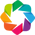

In [10]:
hv.extension("bokeh")

# Set some defaults for the visualization of the graphs
hvopts.defaults(
    hvopts.Image(
        width=800,
        height=600,
        show_title=True,
        tools=["hover"],
        active_tools=["pan", "box_zoom"],
    ),
)

subset_ds['zeta_min'] = subset_ds['zeta'].min(axis=0)

variable, timestamp = "zeta_min", subset_ds.time.values[0]

# The trimesh is the most basic object. This is what you need to create all the others graphs
trimesh = api.create_trimesh(subset_ds.sel(time=timestamp), variable=variable)

# The wireframe is the representation of the mesh
wireframe = api.get_wireframe(trimesh)

# The tiles is using the tiling service from Open Street maps
tiles =  api.get_tiles() 

# The raster object is the basic Map that visualizes the variable. 
raster = api.get_raster(trimesh)\
             .opts(width=800, height = 400, cmap="magma_r", title=variable)
#, clim_min=-1.0, clim_max=0.5

# Create and customize the zeta timeseries plot
tap_dmap_zeta = api.get_tap_timeseries(ds=subset_ds, variable='zeta', source_raster=raster)
tap_dmap_zeta.opts(
    width=800, height=300, title="water elevation",
    xlabel="Time",  # Use default if units not present
    ylabel="Elevation (m)",
    color='blue'  # Set color to blue

)

# Might eventually replace these with hline calls.
tap_dmap_datum_plus = api.get_tap_timeseries(ds=subset_ds, variable='lmsl_minus_mllw_plus', source_raster=raster)
tap_dmap_datum_plus.opts(
    width=800, height=300, title="MLLW",
    xlabel="Time",  # Use default if units not present
    ylabel="Elevation (m)",
    color='green',
    line_width = 0.5
)
tap_dmap_datum_minus = api.get_tap_timeseries(ds=subset_ds, variable='lmsl_minus_mllw_minus', source_raster=raster)
tap_dmap_datum_minus.opts(
    width=800, height=300, title="MLLW",
    xlabel="Time",  # Use default if units not present
    ylabel="Elevation (m)",
    color='green',
    line_width = 0.5
)

timeseries_plot = tap_dmap_zeta * tap_dmap_datum_plus * tap_dmap_datum_minus

flight_path_plot = gv.Path(flight_paths)
flight_image_plot = gv.Points(flight_image_points).opts(color='r', marker='o', size=2)

raster_layout = gv.Layout(tiles * raster * flight_path_plot * flight_image_plot 
                          + timeseries_plot.opts()).cols(1)


In [11]:
raster_layout

:Layout
   .DynamicMap.I  :DynamicMap   []
      :Overlay
         .WMTS.I   :WMTS   [Longitude,Latitude]
         .Image.I  :Image   [lon,lat]   (lon_lat zeta_min)
         .Path.I   :Path   [Longitude,Latitude]   (Project,FlightLine,Emulsion,Scale,SensorType,GroundElev,Feet,Miles,Azimuth,Photos,Canceled)
         .Points.I :Points   [Longitude,Latitude]   (Project,FlightLine,Emulsion,Scale,SensorType,GroundElev,CenterLon,CenterLat,Canceled)
   .DynamicMap.II :DynamicMap   []
      :Overlay
         .Curve.I   :Curve   [x]   (y)
         .Curve.II  :Curve   [x]   (y)
         .Curve.III :Curve   [x]   (y)

In [12]:
# Putting all of the above into a function.
def get_times_in_range(df, range_min, range_max, df_var_name='zeta'):
    # Interpoalate to 1-minute time steps.
    time_steps = (df['time'].values - df['time'].values.min()) / np.timedelta64(1, 's')
    time_interp = np.arange(time_steps.min(), time_steps.max(), 60.0)
    zeta_interp = np.interp(time_interp, time_steps, df[df_var_name].values)
    df_interp = pd.DataFrame(data={df_var_name:zeta_interp}, 
                             index=(time_interp*np.timedelta64(1,'s') 
                                    + df['time'].values.min()))
    
    # Calculate where interpolated zeta is in range.
    df_interp['in_range'] = (df_interp[df_var_name] >= range_min) & (df_interp[df_var_name] <= range_max)

    # Calculate which timesteps are the first and last in range.
    df_interp['first_in_range'] = df_interp['in_range'].copy()
    df_interp['last_in_range'] = df_interp['in_range'].copy()
    df_interp.loc[df_interp.index[0], 'first_in_range'] = df_interp['in_range'].iloc[0].copy()
    df_interp.loc[df_interp.index[-1], 'last_in_range'] = df_interp['in_range'].iloc[-1].copy()
    df_interp.loc[df_interp.index[1:], 'first_in_range'] = ((df_interp.loc[df_interp.index[1:], 'in_range'].values) & 
                                                            (~(df_interp.loc[df_interp.index[:-1], 'in_range'].values)))
    df_interp.loc[df_interp.index[:-1], 'last_in_range'] = ((~df_interp.loc[df_interp.index[1:], 'in_range'].values) & 
                                                            ((df_interp.loc[df_interp.index[:-1], 'in_range'].values)))
    print(df_interp.loc[(df_interp['first_in_range'] == True) | (df_interp['last_in_range'] == True), :])
    
    return df_interp

In [14]:
df_interp = get_times_in_range(
    tap_dmap_zeta.dframe(),
    tap_dmap_datum_minus.dframe()['lmsl_minus_mllw_minus'].iloc[0],
    tap_dmap_datum_plus.dframe()['lmsl_minus_mllw_plus'].iloc[0],
    df_var_name='zeta'
)

                         zeta  in_range  first_in_range  last_in_range
2024-12-17 11:35:00 -0.146509      True            True          False
2024-12-17 13:01:00 -0.244299      True           False           True
2024-12-17 21:44:00 -0.244618      True            True          False
2024-12-17 23:31:00 -0.146076      True           False           True
